![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# Evapotranspiration and the Surface Energy Balance

Evapotranspiration (ET) is the water that leaves the land surface as vapour: evaporation from
soil and open water, transpiration through plant leaves, and evaporation of water intercepted on
leaves. It is the largest outflow of the water balance on irrigated land and the quantity water
managers most want to measure, yet it cannot be seen directly. What satellites can see is its
energy signature: turning liquid water into vapour takes energy, and a surface that evaporates
stays cooler than one that does not. This notebook introduces the surface energy balance behind
every model in this chapter, surveys the family of satellite ET methods used operationally (the
OpenET ensemble and its relatives), and looks at a real Landsat scene of the San Joaquin Valley
in California to see the cool irrigated fields and hot fallow land that anchor these models.

## Overview

### What evapotranspiration is and why it matters

- **Evaporation** from bare soil, wet leaves and open water, and **transpiration**, the water
  plants draw from the root zone and release through their stomata while they take up CO2.
- On irrigated farmland ET is the consumptive use of water: the part that does not return to
  rivers or aquifers. Water rights, groundwater sustainability plans (California's SGMA),
  irrigation scheduling and drought monitoring all depend on it.
- A field measurement of ET (eddy covariance tower, weighing lysimeter) covers a few hectares at
  most. Satellite models extend those point measurements to every field.

### Two ways to look at ET

The **water balance** closes the books on water: `ET = P + I - R - D - dS` (precipitation plus
irrigation minus runoff, drainage and the change in soil storage). Most terms are unknown at the
field scale. The **energy balance** closes the books on energy at the surface:

`Rn = G + H + LE`

| Term | Name | Meaning |
|---|---|---|
| `Rn` | net radiation | shortwave from the sun minus what is reflected, plus longwave from the sky minus what the surface emits |
| `G` | soil heat flux | energy conducted into the ground |
| `H` | sensible heat flux | energy that warms the air above the surface |
| `LE` | latent heat flux | energy used to evaporate water; `L` is the latent heat of vaporization (about 2.45 MJ per kg) and `E` the evaporation rate |

All four are in W m-2. Satellites give `Rn` (from reflectance and temperature) and `G` (from
`Rn` and vegetation) quite well. `H` is the hard part, and `LE` follows as the residual
`LE = Rn - G - H`. That is why these models are called **residual** energy balance models.

### From watts to millimetres

One kilogram of water per square metre is a layer 1 mm deep, so

`ET (mm/h) = 3600 LE / lambda`, with `lambda = (2.501 - 0.00236 T) 10^6` J kg-1 (`T` in C).

A latent heat flux of 680 W m-2 held for an hour evaporates 1 mm. Over a day, 1 mm of ET needs
2.45 MJ m-2, an average of 28.4 W m-2 over 24 hours.

### Typical midday fluxes

| Surface (summer, clear sky) | Rn | G | H | LE |
|---|---|---|---|---|
| Well watered crop, full cover | 550 to 700 | 30 to 80 | -100 to 100 | 450 to 750 |
| Dry bare soil or fallow | 400 to 500 | 80 to 150 | 250 to 400 | 0 to 50 |
| Deep open water | 600 to 700 | stored in the water | small | most of the rest |

`H` can be negative over irrigated crops in a desert: hot dry air flowing over a wet field gives
up heat to it, and LE can then exceed `Rn - G`. This **advection** is common in California and
matters in notebooks 05 and 06.

### Why thermal images

`H = rho cp dT / rah`: sensible heat grows with the difference `dT` between the surface and the
air and shrinks with the aerodynamic resistance `rah`. An evaporating surface spends energy on
LE and stays cool, so its `dT` and `H` are small. Land surface temperature (LST) from a thermal
band is therefore the main signal. Two complications drive the model design:

1. **Radiometric is not aerodynamic temperature.** A thermal sensor sees a mix of sunlit soil and
   canopy, while `H` responds to the temperature at the height where heat is exchanged
   (`z0h`). The difference can be several kelvin over sparse crops.
2. **Air temperature is not known at 30 m.** Weather stations are tens of kilometres apart.

SEBAL and METRIC solve both by never using air temperature directly: they assume `dT` is a linear
function of LST and calibrate the line at two **anchor pixels**, one wet and cool, one dry and
hot (notebooks 05 and 06). Two-source models instead split LST into soil and canopy parts
(notebook 08).

### A family tree of satellite ET methods

| Family | Model | Idea | Main inputs | Used in |
|---|---|---|---|---|
| One-source residual | SEBAL (Bastiaanssen et al. 1998) | `dT = a + b Ts` from hot and cold pixels, no ET at the hot pixel | LST, reflectance, wind | 05 |
| | METRIC (Allen et al. 2007), eeMETRIC | SEBAL with the cold pixel at 1.05 alfalfa reference ET, daily scaling with the reference ET fraction | as SEBAL plus reference ET | 06, OpenET |
| | geeSEBAL (Laipelt et al. 2021) | SEBAL with automated anchors on Earth Engine | as SEBAL | OpenET |
| | SEBS (Su 2002) | physical `H` with roughness for heat and dry and wet limits | LST, air temperature, wind | |
| Simplified and contextual | SSEBop (Senay et al. 2013) | ET fraction from LST between a cold limit (`c Tmax`) and a hot limit `Tc + dT` | LST, Tmax, NDVI, reference ET | 07, OpenET |
| | S-SEBI (Roerink et al. 2000) | dry and wet edges in the albedo and LST scatter | LST, albedo | 07 |
| | Triangle (Jiang and Islam 2001) | Priestley-Taylor parameter from the LST and vegetation triangle | LST, NDVI | 07 |
| Priestley-Taylor | PT-JPL (Fisher et al. 2008) | potential ET reduced by plant and soil moisture constraints | Rn, NDVI, air temperature, humidity | 07, OpenET |
| Two-source | TSEB (Norman et al. 1995), ALEXI and DisALEXI (Anderson et al. 1997, 2018) | soil and canopy temperatures and fluxes; ALEXI uses the morning rise in temperature from geostationary satellites | LST, LAI, air temperature, wind | 08, OpenET |
| Penman-Monteith | MOD16 (Mu et al. 2011) | Penman-Monteith with surface conductances from LAI and weather | LAI, weather | 09, 11 |
| Crop coefficient | SIMS (Melton et al. 2012) | crop coefficient from fraction of cover times reference ET, no thermal band | NDVI, crop type, reference ET | OpenET |

**OpenET** (Melton et al. 2022) runs six of these models (ALEXI/DisALEXI, eeMETRIC, geeSEBAL,
PT-JPL, SIMS and SSEBop) on Landsat for the western United States and publishes their ensemble.
Its accuracy assessment against flux towers (Volk et al. 2024) found that the ensemble was among
the most accurate estimates over croplands, while single models did better or worse depending on
crop and season. This chapter writes each model from its equations so you can see where those
differences come from.

### From an instant to a season

A Landsat image is a snapshot at about 10:30 to 11:30 local time. Two assumptions carry it to a
whole day:

- **Evaporative fraction** `EF = LE / (Rn - G)` stays constant during the day (SEBAL).
- **Reference ET fraction** `ETrF = ET / ETr` stays constant, where `ETr` is the ET of a well
  watered alfalfa reference computed from weather (METRIC). This also carries the effect of
  advection and of cloudy afternoons through the reference.

Between clear images, the fraction (not ET itself) is interpolated in time and multiplied by the
daily reference ET (notebook 10).

## The Surface Energy Balance with GeoLattice

`geolattice.rsense.surface_energy_balance` (imported as `seb`) implements every step of the
chapter. Its functions take NumPy arrays or xarray DataArrays and keep units in their
attributes; model runs return an `xr.Dataset` on the Landsat grid.

| Step | Functions | Notebook |
|---|---|---|
| Scene metadata and weather | `seb.scene_geometry`, `seb.weather_open_meteo`, `seb.interpolate_weather` | 01 |
| Reference ET | `seb.asce_pm_hourly`, `seb.asce_pm_daily` | 02 |
| Net radiation | `seb.albedo`, `seb.leaf_area_index`, `seb.surface_emissivity`, `seb.net_radiation` | 03 |
| Soil heat and aerodynamics | `seb.soil_heat_flux`, `seb.momentum_roughness`, `seb.aerodynamic_resistance`, `seb.stability_corrections` | 04 |
| Models | `seb.run_sebal`, `seb.run_metric`, `seb.run_ssebop`, `seb.ssebi`, `seb.triangle_method`, `seb.priestley_taylor_jpl`, `seb.tseb_pt` | 05 to 08 |
| Other sensors, seasons, accuracy | `seb.thermal_sharpen`, `seb.interpolate_etrf`, `seb.seasonal_et`, `seb.zonal_et`, `seb.compare_to_tower` | 09 to 12 |

The chapter helper `seb_data.py` (imported as `sd`) downloads and caches the scenes, so each
notebook runs on its own. `sd.load_scene` returns one analysis-ready Landsat stack, and
`sd.energy_inputs` and `sd.run_metric_scene` repeat the chain of notebooks 03 to 06 for the later
notebooks.

### Learning objectives

1. Define ET and its parts, and convert between latent heat flux (W m-2) and ET (mm).
2. Write the surface energy balance and give typical values of each term over crops, soil and
   water.
3. Explain why land surface temperature is the key signal and why air temperature is avoided.
4. Place SEBAL, METRIC, SSEBop, S-SEBI, PT-JPL, TSEB, MOD16 and SIMS in a family tree, and say
   what each needs.
5. Read a Landsat scene's NDVI and LST and recognise the wet and dry ends of the LST and NDVI
   scatter.
6. Run METRIC once and check that `Rn = G + H + LE` holds for crops and fallow land.

### Data

| Dataset | Content |
|---|---|
| Landsat 8 Collection 2 Level-2, `LC08_L2SP_042035_20240705_02_T1` | 5 July 2024, 18:33 UTC (11:33 local), path 42 row 35; surface reflectance and surface temperature over the Westside San Joaquin Valley around Five Points (about 28 x 29 km at 30 m), from Microsoft Planetary Computer |
| USDA Cropland Data Layer 2024 | crop type of every 30 m pixel, from CropScape |
| Copernicus DEM GLO-30 | elevation |
| ERA5 hourly and daily weather | from the Open-Meteo archive, at the scene centre |

The first run downloads about 25 MB and caches it under
`Data/08_remote_sensing/08_12_surface_energy_balance/westside/`.

### Contents

- Setup
- The scene
- Crops, fallow land and temperature
- The LST and NDVI scatter
- The energy balance of crops and fallow land
- From flux to millimetres
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217, 66, 67, 72], "Grapes": [69],  # CDL codes per crop group
          "Annual crops": [54, 2, 1, 36, 37, 208, 49, 209, 47, 227, 225, 24, 21, 28, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152, 131], "Developed": [121, 122, 123, 124]}
COLORS = {"Tree crops": "#1b7837", "Grapes": "#7b3294", "Annual crops": "#5aae61",  # one colour per group
          "Fallow": "#b35806", "Grass and shrubs": "#e0a24a", "Developed": "#636363"}

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## The scene

`sd.load_scene()` returns the stack notebook 01 builds: six reflectance bands, the Collection 2
surface temperature (`lst`, K), the thermal radiance terms, a clear-sky mask from `QA_PIXEL`,
elevation, the 2024 crop map and the weather at the overpass in the attributes.

In [2]:
ds = sd.load_scene()  # Landsat 8, 5 July 2024, Westside San Joaquin Valley
print(ds.attrs["scene_id"], "|", ds.attrs["datetime"], "UTC |", dict(ds.sizes), "| CRS", ds.rio.crs)  # what was loaded
print(f"clear pixels {float(ds.clear.mean()):.1%} | sun elevation {ds.attrs['sun_elevation']:.1f} deg")  # cloud-free share and sun
print(f"ERA5 at overpass: air {ds.attrs['t_air_c']:.1f} C, RH {ds.attrs['rh']:.0f} %, wind {ds.attrs['u10']:.1f} m/s, "
      f"shortwave {ds.attrs['rs_wm2']:.0f} W/m2 | daily max {ds.attrs['tmax_c']:.1f} C")  # weather in the attributes

LC08_L2SP_042035_20240705_02_T1 | 2024-07-05 18:33:27.252130 UTC | {'y': 953, 'x': 926} | CRS EPSG:32611
clear pixels 100.0% | sun elevation 66.5 deg
ERA5 at overpass: air 39.8 C, RH 9 %, wind 2.2 m/s, shortwave 854 W/m2 | daily max 46.6 C


The overpass came during the early July 2024 heat wave: ERA5 gives a daily maximum above 46 C at
the scene centre (gridMET, used in notebook 02, gives 42 C), 9 % relative humidity at the time
of the image and full sunshine. These are conditions of very high evaporative demand.

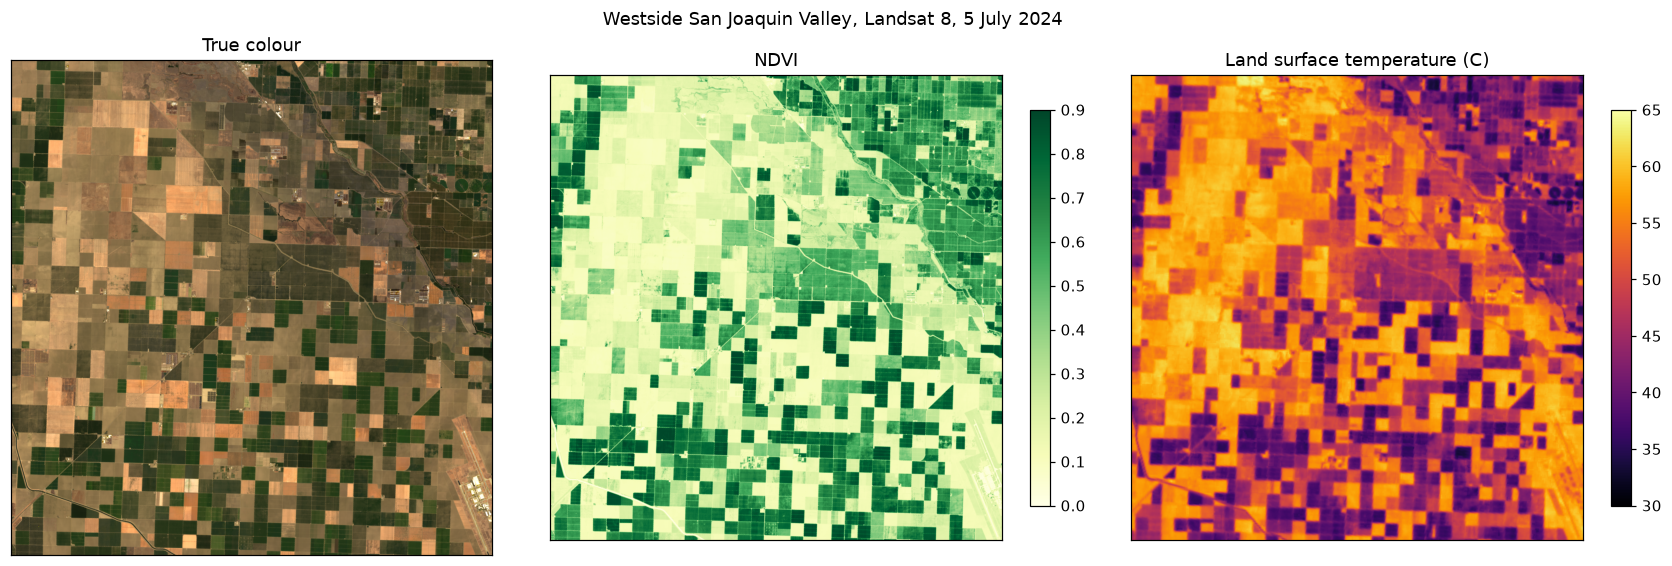

In [3]:
m = ds.clear.astype(bool)  # clear-sky pixels
ndvi = seb.ndvi(ds.red, ds.nir).where(m)  # NDVI
lst_c = (ds.lst - 273.15).where(m)  # surface temperature in C
rgb = np.clip(np.dstack([ds.red, ds.green, ds.blue]) * 3.0, 0, 1)  # stretched true colour
ext = [float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())]  # map extent

fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))  # three maps
ax[0].imshow(rgb, extent=ext); ax[0].set_title("True colour")  # image
im = ax[1].imshow(ndvi, extent=ext, cmap="YlGn", vmin=0, vmax=0.9); ax[1].set_title("NDVI")  # vegetation
plt.colorbar(im, ax=ax[1], shrink=0.8)  # NDVI scale
im = ax[2].imshow(lst_c, extent=ext, cmap="inferno", vmin=30, vmax=65); ax[2].set_title("Land surface temperature (C)")  # LST
plt.colorbar(im, ax=ax[2], shrink=0.8)  # LST scale
for a in ax:  # every map
    a.set_xticks([]); a.set_yticks([])  # hide coordinates
plt.suptitle("Westside San Joaquin Valley, Landsat 8, 5 July 2024"); plt.tight_layout(); plt.show()  # draw

## Crops, fallow land and temperature

The crop map assigns every pixel a CDL class. Grouping the classes into tree crops, grapes,
annual crops, fallow, rangeland and developed land shows how surface temperature follows water
use.

In [4]:
group = xr.full_like(ds.cdl, -1, dtype="int8")  # crop group index per pixel
for i, codes in enumerate(GROUPS.values()):  # every group
    group = group.where(~ds.cdl.isin(codes), i)  # pixels whose CDL code is in the group
names = list(GROUPS)  # group names in order
tab = pd.DataFrame({"group": group.values.ravel(), "ndvi": ndvi.values.ravel(), "lst_c": lst_c.values.ravel()}).dropna()  # one row per pixel
tab = tab[tab.group >= 0]  # keep grouped pixels
tab["group"] = tab.group.map(dict(enumerate(names)))  # group names
summary = tab.groupby("group").agg(share=("ndvi", "size"), ndvi=("ndvi", "median"), lst_c=("lst_c", "median"))  # medians per group
summary["share"] = (100 * summary.share / m.sum().item()).round(1)  # percent of the scene
summary.loc[names].round(2)  # table in group order

,share,ndvi,lst_c
group,,,
Tree crops,28.0,0.48,47.19
Grapes,6.3,0.63,44.03
Annual crops,31.7,0.33,48.53
Fallow,16.5,0.12,57.90
Grass and shrubs,5.7,0.21,56.30
Developed,6.3,0.18,54.20


In the medians, fallow land is 9 to 14 K hotter than the tree crops, grapes and annual crops,
and rangeland and developed land are nearly as hot as fallow. Grapes, the greenest group, are
also the coolest. The groups overlap: tree orchards include young plantings and wide rows of bare
soil between the trees, and annual crops include fields that were just harvested or planted.
The scatter of all pixels shows the overall structure.

## The LST and NDVI scatter

Plotting LST against NDVI gives the characteristic triangle or trapezoid of energy balance
studies. Its cool upper right corner holds dense, well watered vegetation (the **cold anchor**
region), its hot lower left corner dry bare soil (the **hot anchor** region). The upper edge of
the cloud, hottest LST for each NDVI, is the **dry edge**; the cool lower boundary, the **wet
edge**.

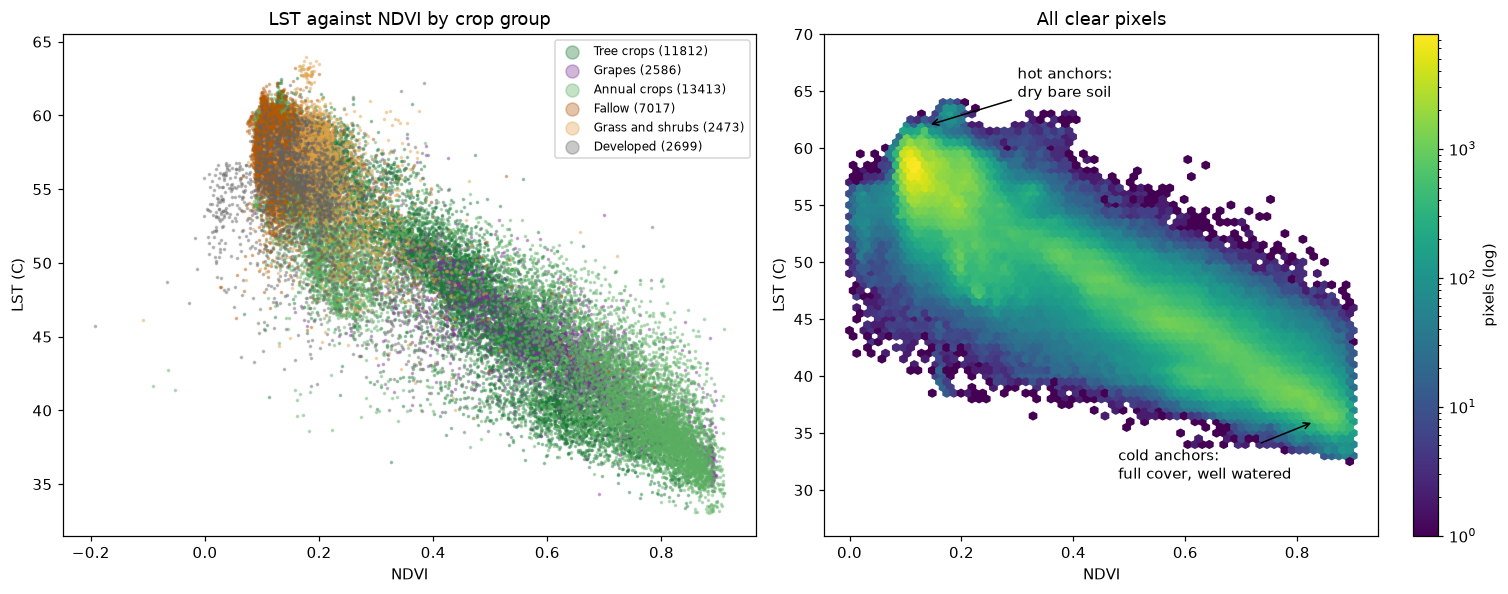

correlation of LST and NDVI: -0.93


In [5]:
sample = tab.sample(40000, random_state=0)  # a random subset for plotting
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))  # scatter and density
for g in names:  # every crop group
    s = sample[sample.group == g]  # its pixels
    ax[0].scatter(s.ndvi, s.lst_c, s=2, alpha=0.35, color=COLORS[g], label=f"{g} ({len(s)})")  # points
ax[0].set_xlabel("NDVI"); ax[0].set_ylabel("LST (C)"); ax[0].legend(markerscale=6, fontsize=8)  # labels
ax[0].set_title("LST against NDVI by crop group")  # title
h = ax[1].hexbin(tab.ndvi, tab.lst_c, gridsize=70, bins="log", cmap="viridis", extent=(0, 0.9, 28, 68))  # density of all pixels
plt.colorbar(h, ax=ax[1], label="pixels (log)")  # scale
ax[1].annotate("cold anchors:\nfull cover, well watered", (0.83, 36), xytext=(0.48, 31), arrowprops=dict(arrowstyle="->"))  # wet corner
ax[1].annotate("hot anchors:\ndry bare soil", (0.14, 62), xytext=(0.3, 64.5), arrowprops=dict(arrowstyle="->"))  # dry corner
ax[1].set_xlabel("NDVI"); ax[1].set_ylabel("LST (C)"); ax[1].set_title("All clear pixels")  # labels
plt.tight_layout(); plt.show()  # draw
print("correlation of LST and NDVI:", round(float(np.corrcoef(tab.ndvi, tab.lst_c)[0, 1]), 2))  # strength of the relation

LST falls by about 25 K from bare soil (near 60 C) to full cover (near 35 C), and the strong
negative correlation (-0.93) is the evaporative cooling the models use. The spread at a given
NDVI is just as informative: at NDVI 0.3 the coolest pixels are close to 20 K cooler than the
hottest, because a sparse canopy over wet soil
evaporates far more than the same canopy over dry soil. NDVI alone (as in crop coefficient
methods) cannot see that difference; the thermal band can.

`seb.select_anchors` searches the two corners automatically with the Allen et al. (2013)
percentile rules (notebook 05 explains them):

In [6]:
inp = sd.energy_inputs(ds)  # NDVI, albedo, net radiation, soil heat flux, roughness, anchors (notebooks 03 and 04)
seb.anchor_report(inp["anchors"]).assign(lst_c=lambda d: d.lst - 273.15,  # anchor table in C
                                         crop=lambda d: [sd.cdl_name(ds.cdl.values[r.iy, r.ix]) for r in d.itertuples()])  # crop at each anchor

,iy,ix,n_candidates,x,y,ndvi,lst,albedo,lst_c,crop
anchor,,,,,,,,,,
cold,193,25,3636,208920.0,4044060.0,0.832008,308.385681,0.191459,35.235681,Almonds
hot,206,193,11899,213960.0,4043670.0,0.109267,333.186829,0.184831,60.036829,Other hay


The cold anchor fell in an almond orchard at full cover (NDVI 0.83, 35 C) and the hot anchor in
a harvested hay field (NDVI 0.11, 60 C): cut hay leaves dry stubble, a good dry reference.

## The energy balance of crops and fallow land

`sd.run_metric_scene` runs METRIC (notebook 06) with the chapter defaults. The result gives `H`
and `LE` for every pixel; together with `Rn` and `G` from the inputs, the four terms of the
energy balance can be compared by crop group.

In [7]:
res = sd.run_metric_scene(ds, inp)  # METRIC: H, LE, ETrF and daily ET
fluxes = xr.Dataset({"Rn": inp["rn"], "G": inp["g"], "H": res.h, "LE": res.le})  # the four terms
residual = float(np.nanmax(np.abs(fluxes.Rn - fluxes.G - fluxes.H - fluxes.LE)))  # Rn - G - H - LE
print(f"largest |Rn - G - H - LE| = {residual:.1e} W/m2 (LE is the residual by construction)")  # balance check
by = fluxes.assign(group=group).to_dataframe()[["Rn", "G", "H", "LE", "group"]].dropna()  # one row per pixel
by = by[by.group >= 0].groupby("group").mean().rename(index=dict(enumerate(names)))  # mean fluxes per crop group
by.loc[names].round(0)  # W/m2 at the overpass

largest |Rn - G - H - LE| = 0.0e+00 W/m2 (LE is the residual by construction)


,Rn,G,H,LE
group,,,,
Tree crops,566.0,99.0,42.0,426.0
Grapes,554.0,69.0,-14.0,499.0
Annual crops,515.0,93.0,62.0,360.0
Fallow,485.0,144.0,237.0,104.0
Grass and shrubs,479.0,139.0,182.0,157.0
Developed,501.0,133.0,123.0,245.0


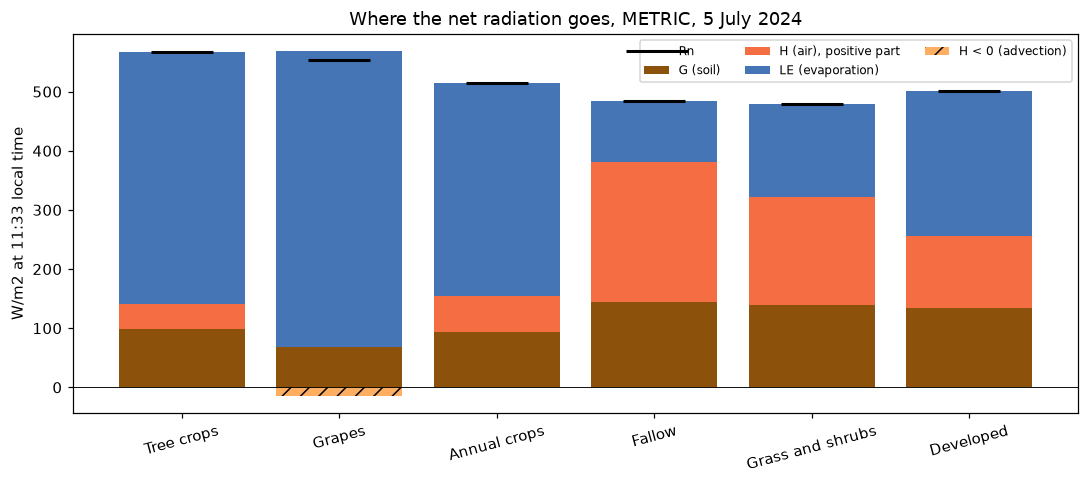

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))  # one panel
order = by.loc[names]  # groups in order
x = np.arange(len(order))  # bar positions
ax.bar(x, order.G, color="#8c510a", label="G (soil)")  # soil heat flux
ax.bar(x, order.H.clip(lower=0), bottom=order.G, color="#f46d43", label="H (air), positive part")  # sensible heat above G
ax.bar(x, order.LE, bottom=order.G + order.H.clip(lower=0), color="#4575b4", label="LE (evaporation)")  # latent heat on top
ax.bar(x, order.H.clip(upper=0), color="#fdae61", hatch="//", label="H < 0 (advection)")  # negative H below zero
ax.plot(x, order.Rn, "k_", markersize=40, mew=2, label="Rn")  # net radiation
ax.set_xticks(x); ax.set_xticklabels(order.index, rotation=15); ax.axhline(0, color="k", lw=0.6)  # labels
ax.set_ylabel("W/m2 at 11:33 local time"); ax.legend(fontsize=8, ncol=3, loc="upper right")  # axes
ax.set_title("Where the net radiation goes, METRIC, 5 July 2024"); plt.tight_layout(); plt.show()  # draw

Fallow land and rangeland send most of their available energy into the air as sensible heat;
the vegetated crops send most of theirs into evaporation. The darker surfaces also absorb more:
net radiation is higher over crops than over bright dry soil, which reflects more sunlight and
emits more longwave at its higher temperature. Grapes have a negative mean `H` (-14 W m-2): on
average the vineyards draw heat from the hot air, the advection described in the Overview, and
their LE (499 W m-2) is larger than `Rn - G`. Fallow land still averages about 100 W m-2 of LE:
METRIC gives exactly zero ET only to pixels as hot as the hot anchor, and some fields mapped as
fallow in the 2024 CDL had a cover crop or were irrigated in another part of the year.

## From flux to millimetres

The instantaneous ET at the overpass is `3600 LE / lambda` (mm/h). METRIC then scales the
reference ET fraction to the day with the daily alfalfa reference ET (here from ERA5, notebook
02).

In [9]:
print(f"1 mm/h needs LE = {2.45e6 / 3600:.0f} W/m2; 1 mm/day needs {2.45e6 / 86400:.1f} W/m2 on average")  # conversions
print(f"alfalfa reference ET: {res.attrs['etr_inst']:.2f} mm/h at the overpass, {res.attrs['etr_daily']:.1f} mm for the day")  # reference ET
et = res[["et_inst", "etrf", "et24"]].assign(group=group).to_dataframe()[["et_inst", "etrf", "et24", "group"]].dropna()  # per pixel
et = et[et.group >= 0].groupby("group").median().rename(index=dict(enumerate(names)))  # median per crop group
et.loc[names].round(2).rename(columns={"et_inst": "ET at overpass (mm/h)", "etrf": "ETrF", "et24": "daily ET (mm)"})  # table

1 mm/h needs LE = 681 W/m2; 1 mm/day needs 28.4 W/m2 on average
alfalfa reference ET: 0.93 mm/h at the overpass, 15.6 mm for the day


,ET at overpass (mm/h),ETrF,daily ET (mm)
group,,,
Tree crops,0.73,0.78,12.19
Grapes,0.78,0.84,13.07
Annual crops,0.59,0.63,9.85
Fallow,0.14,0.15,2.34
Grass and shrubs,0.22,0.23,3.62
Developed,0.35,0.38,5.89


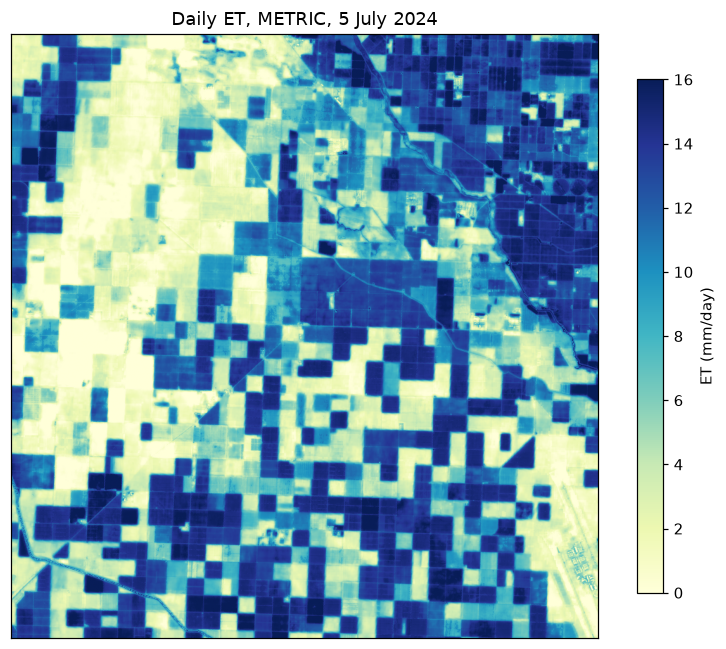

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 6))  # one map
im = ax.imshow(res.et24, extent=ext, cmap="YlGnBu", vmin=0, vmax=16)  # daily ET map
plt.colorbar(im, ax=ax, shrink=0.85, label="ET (mm/day)")  # scale
ax.set_title("Daily ET, METRIC, 5 July 2024"); ax.set_xticks([]); ax.set_yticks([])  # title
plt.tight_layout(); plt.show()  # draw

The daily map shows individual fields. On a day with an alfalfa reference of 15.6 mm, the median
tree crop pixel used about 12 mm and the median vineyard about 13 mm, while fallow land used about
2 mm. These are heat wave values, well above the 7 to 9 mm typical of orchards in an ordinary
July.

## Summary and exercises

- ET is the energy-limited and water-limited loss of water as vapour. Converting with `lambda`,
  680 W m-2 for one hour is 1 mm, and 28.4 W m-2 for a day is 1 mm.
- Satellites estimate `Rn` and `G` well; the models differ in how they find `H`, and `LE` is the
  residual.
- Land surface temperature carries the signal: on 5 July 2024 the fallow median was 9 to 14 K
  hotter than the crop groups, LST fell by about 25 K from bare soil to full cover, and LST and
  NDVI had a correlation of -0.93.
- Anchor pixels at the cool, dense and hot, bare ends of the LST and NDVI scatter calibrate SEBAL
  and METRIC.
- The instantaneous fraction (EF or ETrF) is carried to a day and a season with reference ET.

**Exercises**

1. Repeat the crop group table with the dry edge in mind: for each group, what fraction of
   pixels has LST within 3 K of the hottest LST for its NDVI bin? What does that say about water
   stress?
2. Compute the evaporative fraction `LE / (Rn - G)` for each group. Which groups exceed 1, and
   why is that possible?
3. Load an April scene (`sd.load_scene("LC09_L2SP_042035_20240408_02_T1")`) and redraw the LST
   and NDVI scatter. How do the two corners move between spring and midsummer?
4. Convert the scene mean daily ET to a volume of water in cubic metres for the 28 x 29 km
   window.